# Curso: Redes Neurais Convolucionais

Prof. [Denilson Alves Pereira](https://sites.google.com/ufla.br/denilsonpereira) <br>
Departamento de Ciência da Computação (DCC) <br>
Instituto de Ciências Exatas e Tecnológicas (ICET) <br> 
Universidade Federal de Lavras (UFLA)

## Reconhecimento Facial

Reconhecimento facial é uma tarefa da visão computacional que tem como objetivo identificar e verificar uma pessoa baseado em uma fotografia de seu rosto.

Problemas de reconhecimento facial normalmente podem ser divididos em duas categorias:

- **Verificação Facial (*Face Verification*)**: verifica se a pessoa na imagem da câmera é a mesma de uma imagem pré-cadastrada. Por exemplo, para entrar na portaria de uma empresa, o funcionário passa o crachá de identificação e uma câmera tira usa foto. Sua entrada vai ser permitida se a foto tirada for similar à foto já pré-cadastrada da pessoa identificada pelo crachá. Outro exemplo é o desbloqueio de um celular por imagem facial. Esse é um problema de casamento (*matching*) 1:1.

- **Reconhecimento Facial (*Face Recognition*)**: verifica quem é a pessoa da imagem da câmera consultando um banco de dados de pessoas pré-cadastradas. Por exemplo, um funcionário para entrar na portaria de sua empresa tem sua foto tirada e depois comparada com as fotos de todos os funcionários pré-cadastrados em um banco de dados. O sistema reconhece quem é o funcionário que está entrando, ou se ele não é um funcionário cadastrado. Outro exemplo, marcar as pessoas em fotos postadas em uma rede social. Essé é um problema de casamento (*matching*) 1:N.

**Objetivo**: apresentar um exemplo de aplicação de reconhecimento facial baseado no sistema [FaceNet](https://arxiv.org/pdf/1503.03832.pdf).

**Você vai aprender a**:
- Utilizar um modelo pré-treinado do FaceNet para mapear imagens de faces em codificações de 128 dimensões
- Formatar e normalizar as imagens para usarem o modelo pré-treinado
- Usar as codificações para executar as tarefas de verficação facial e de reconhecimento facial
- Implementar um classificador tradicional para reconhecimento facial

Versão: Agosto, 2021

## Pacotes

In [1]:
import numpy as np # scientific computing
import tensorflow as tf  #  numerical computation using data flow graphs
from tensorflow import keras  # deep learning
import matplotlib.pyplot as plt # scientific plotting library
from sklearn.preprocessing import Normalizer
import cv2 # OpenCV library for computer vision problems
from PIL import Image # Python Imaging Library

## Inicializações

In [2]:
IMAGE_HEIGHT = 160 # altura da imagem (facenet)
IMAGE_WIDTH = 160  # largura da imagem (facenet)
IMAGE_SIZE = (IMAGE_HEIGHT, IMAGE_WIDTH) # tamanho da imagem
IMAGE_CHANNELS = 3  # número de canais RGB da imagem
DIR_DATA = '/home/denilson/Downloads/datasets/image-recognition/'  # diretório contendo as imagens

## Leitura e Pré-Processamento dos Dados

**Dataset**: ORL Face, composto de 400 imagens de tamanho 112 x 92, em escala de cinza. Há 20 pessoas e 20 imagens por pessoa, sendo 60% para treino e 40% para teste. As imagens foram tiradas em épocas diferentes, em diferentes tonalidades de luz e expressões faciais. Cada imagem contém apenas uma face (visão frontal).

O código abaixo contém algumas partes adaptadas de https://www.kaggle.com/prakharprasad/facerecognition-facenet-cnnclassifier

In [3]:
# Read dataset
data = np.load(DIR_DATA+'ORL_faces.npz')

In [4]:
# The data is already divided into training and testing
data.files

['testY', 'testX', 'trainX', 'trainY']

In [5]:
data['trainX']

array([[ 48.,  49.,  45., ...,  47.,  46.,  46.],
       [ 60.,  60.,  62., ...,  32.,  34.,  34.],
       [ 39.,  44.,  53., ...,  29.,  26.,  29.],
       ...,
       [114., 117., 114., ...,  98.,  96.,  98.],
       [105., 105., 107., ...,  54.,  47.,  41.],
       [116., 114., 117., ...,  95., 100., 101.]])

In [6]:
# Train: 12 imagens for each person
data['trainY']

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  2,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  4,  4,  4,
        4,  4,  4,  4,  4,  4,  4,  4,  4,  5,  5,  5,  5,  5,  5,  5,  5,
        5,  5,  5,  5,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  7,
        7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,  8,  8,
        8,  8,  8,  8,  8,  8,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,
        9, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11,
       11, 11, 11, 11, 11, 11, 11, 11, 12, 12, 12, 12, 12, 12, 12, 12, 12,
       12, 12, 12, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 14, 14,
       14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15, 15, 15, 15, 15,
       15, 15, 15, 15, 15, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16,
       17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 18, 18, 18, 18, 18,
       18, 18, 18, 18, 18

In [7]:
data['trainX'].shape, data['trainY'].shape

((240, 10304), (240,))

In [8]:
# Test: 8 imagens for each person
data['testY']

array([ 0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,  1,  1,  1,  2,
        2,  2,  2,  2,  2,  2,  2,  3,  3,  3,  3,  3,  3,  3,  3,  4,  4,
        4,  4,  4,  4,  4,  4,  5,  5,  5,  5,  5,  5,  5,  5,  6,  6,  6,
        6,  6,  6,  6,  6,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,
        8,  8,  8,  8,  9,  9,  9,  9,  9,  9,  9,  9, 10, 10, 10, 10, 10,
       10, 10, 10, 11, 11, 11, 11, 11, 11, 11, 11, 12, 12, 12, 12, 12, 12,
       12, 12, 13, 13, 13, 13, 13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 14,
       14, 15, 15, 15, 15, 15, 15, 15, 15, 16, 16, 16, 16, 16, 16, 16, 16,
       17, 17, 17, 17, 17, 17, 17, 17, 18, 18, 18, 18, 18, 18, 18, 18, 19,
       19, 19, 19, 19, 19, 19, 19], dtype=uint8)

In [9]:
data['testX'].shape, data['testY'].shape

((160, 10304), (160,))

#### Usaremos apenas os dados de treino para verificação e reconhecimento facial

In [10]:
# Images are in a flat vector of size 112 x 92 = 10,304
n_rows = 112
n_cols = 92
n_channels = 1

# Reshape vector to 112 x 92 x 3 dimension
dataX =  np.reshape(data['trainX'],newshape=(data['trainX'].shape[0],n_rows,n_cols))
dataX = np.array(list(map(lambda p: cv2.cvtColor(p, cv2.COLOR_GRAY2BGR), np.float32(dataX))))/255.
dataY = data['trainY']

In [11]:
dataX.shape

(240, 112, 92, 3)

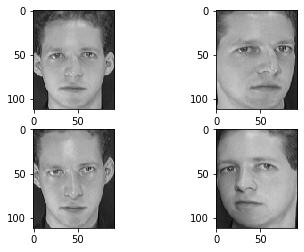

In [12]:
# plot some faces 
plt.subplot(2,2,1)
plt.imshow(dataX[0])
plt.subplot(2,2,2)
plt.imshow(dataX[1])
plt.subplot(2,2,3)
plt.imshow(dataX[2])
plt.subplot(2,2,4)
plt.imshow(dataX[3])
plt.show()

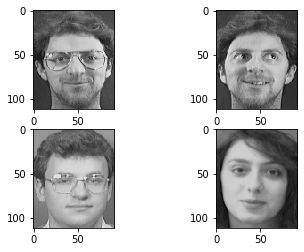

In [13]:
# Visualize random images
delta = 5
n = np.random.randint(low=0,high=dataX.shape[0]-2*delta,dtype=int)
# plot the faces 
plt.subplot(2,2,1)
plt.imshow(dataX[n])
plt.subplot(2,2,2)
plt.imshow(dataX[n+delta])
plt.subplot(2,2,3)
plt.imshow(dataX[n-delta])
plt.subplot(2,2,4)
plt.imshow(dataX[n+delta*2])
plt.show()

## Geração de *Embeddings* usando o FaceNet

- A verificação e reconhecimento facial serão feitos a partir de um modelo pré-treinado do sistema [FaceNet](https://arxiv.org/pdf/1503.03832.pdf). Treinar um bom modelo de reconhecimento facial exige um número muito grande de imagens e um alto poder computacional.
- O modelo FaceNet foi treinado usando a função *Triplet Loss*. Essa função tem como objetivo aproximar as codificações de duas imagens da mesma pessoa (âncora e positivo), enquanto distancia as codificações de duas imagens de pessoas diferentes (âncora e negativo).
- O modelo FaceNet gera *embeddings* para cada imagem facial. Os *embeddings* são vetores com 128 elementos. A rede usa imagens RGB de dimensão 160x160 como entrada e produz como saída vetores de 128 elementos, os quais codificam cada imagem de face de entrada.
- O vetor de codificação de tamanho 128 é obtido por meio de uma camada completamente conectada com 128 neurônios como a última camada da rede.
- A vantagem de se gerar *embeddings* é uma computação mais rápida. Os *embeddings* podem ser usados como entrada para um classificador tradicional para o reconhecimento facial, em vez de se usar as imagens originais.

### FaceNet *Triplet Loss*

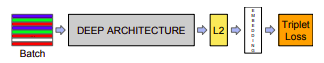
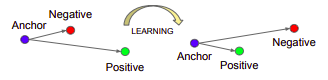

O treinamento da rede neural usa trios de imagens $(A, P, N)$:
- A é uma imagem "Âncora" - a imagem de uma pessoa
- P é uma imagem "Positiva" - a imagem da mesma pessoa que a imagem âncora
- N é uma imagem "Negativa" - a imagem de uma pessoa diferente daquela da imagem âncora

Considere que $(A^{(i)}, P^{(i)}, N^{(i)})$ denota o $i$-ésimo exemplo de treino. A imagem âncora $A^{(i)}$ de uma pessoa deve estar mais próxima da imagem Positiva $P^{(i)}$ do que da imagem Negativa $N^{(i)}$) por, pelo menos, uma margem $\alpha$:

$$\mid \mid f(A^{(i)}) - f(P^{(i)}) \mid \mid_2^2 + \alpha < \mid \mid f(A^{(i)}) - f(N^{(i)}) \mid \mid_2^2$$

O objetivo é minimizar a função de custo "triplet cost":

$$\mathcal{J} = \sum^{m}_{i=1} max(\small \underbrace{\mid \mid f(A^{(i)}) - f(P^{(i)}) \mid \mid_2^2}_\text{(1)} - \underbrace{\mid \mid f(A^{(i)}) - f(N^{(i)}) \mid \mid_2^2}_\text{(2)} + \alpha, 0) \tag{3}$$

- Para uma imagem $x$, a codificação $f(x)$ é a função computada pela rede neural.
- O termo (1) é a distância ao quadrado entre a âncora "A" e a imagem positiva "P" para um dado trio. O objetivo é que essa distância seja pequena.
- O termo (2) é a distância ao quadrado entre a âncora "A" e a imagem negativa "N" para um dado trio. O objetivo é que essa distância seja relativamente grande. O termo tem um sinal negativo o precedendo, assim, minimizar o negativo do termo é o mesmo que maximizar o termo.
- $\alpha$ é chamado de margem. Ela é um hiperparâmetro que deve ser especificado manualmente. Um valor usual é $\alpha = 0.2$. 
- A maioria das implementações redimensiona os vetores codificados para terem a norma L2 igual a 1 (i.e., $\mid \mid f(img)\mid \mid_2$=1).

In [14]:
# load the pretrained facenet model
model = tf.keras.models.load_model(DIR_DATA+'facenet/model/facenet_keras.h5', compile=False)
print(model.inputs)
print(model.outputs)

[<KerasTensor: shape=(None, 160, 160, 3) dtype=float32 (created by layer 'input_1')>]
[<KerasTensor: shape=(None, 128) dtype=float32 (created by layer 'Bottleneck_BatchNorm')>]


In [15]:
# check the current shape
dataX.shape

(240, 112, 92, 3)

In [16]:
# resize the array to make it compatible with facenet
resized_dataX = np.zeros((dataX.shape[0], IMAGE_HEIGHT, IMAGE_WIDTH, IMAGE_CHANNELS))
for i in range(dataX.shape[0]):
    img = Image.fromarray((dataX[i]*255).astype(np.uint8), 'RGB')
    img = img.resize((IMAGE_SIZE))
    resized_dataX[i] = np.asarray(img)/255.

In [17]:
# check the new shape after array resize
resized_dataX.shape

(240, 160, 160, 3)

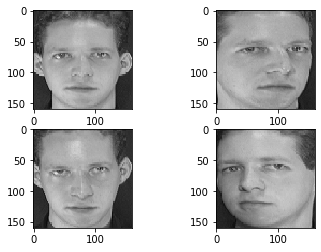

In [18]:
# plot some faces 
plt.subplot(2,2,1)
plt.imshow(resized_dataX[0])
plt.subplot(2,2,2)
plt.imshow(resized_dataX[1])
plt.subplot(2,2,3)
plt.imshow(resized_dataX[2])
plt.subplot(2,2,4)
plt.imshow(resized_dataX[3])
plt.show()

In [19]:
# use the pretrained model to generate the embeddings 
dataY_embeddings = model.predict(resized_dataX)

In [20]:
dataY_embeddings.shape

(240, 128)

#### Normalização dos Embeddings

É uma boa prática normalizar os vetores de embeddings, pois os vetores são comparados uns com os outros usando-se uma métrica de distância. A distância Euclidiana é uma das métricas mais usadas quando as variáveis são de tipos similares, como é o caso das imagens faciais. A distância Euclidiana é a distância mais curta entre dois pontos em um espaço N-dimensional (Espaço Euclidiano). Ela é também conhecida como Norma Euclidiana, Métrica Euclidiana, Norma L2, Métrica L2 e Métrica Pitagoreana.

Por definição, a norma L2 é a distância euclidiana entre o ponto do vetor e a sua origem. Ela é calculada como a raiz quadrada da soma dos quadrados dos valores do vetor. Já a distância (métrica) entre dois vetores (dois pontos) pode ser definida como a norma da diferença desses dois vetores. Assim, distância é sempre entre dois pontos e norma é sempre para um vetor. Mais detalhes neste link: https://paulrohan.medium.com/euclidean-distance-and-normalization-of-a-vector-76f7a97abd9

Normalização de dados é usada em aprendizagem de máquina para tornar o modelo de treinamento menos sensível à escala das medidas. Isso permite ao modelo convergir para melhores pesos e, consequentemente, conduz a um modelo mais preciso. Normalizar um vetor em matemática é dividir cada um dos seus elementos por algum valor V, de forma que o comprimento/norma do vetor resultante seja igual a 1. Isso faz com que V seja igual ao comprimento do vetor.

A Normalização L2 é definida como a técnica de normalização que modifica os valores do dataset de forma que em cada linha a raiz quadrada da soma dos quadrados de seus valores seja igual a 1. É também chamada de quadrados mínimos.

In [21]:
# apply the L2 norm on the generated embeddings
input_encoder = Normalizer(norm='l2')
dataY_embeddings = input_encoder.transform(dataY_embeddings)

## Verificação Facial (*Face Verification*)

A tarefa de verificação facial certifica se a pessoa na imagem da câmera é a mesma de uma imagem pré-cadastrada (imagem de referência).

Neste exemplo, vamos criar um banco de dados (*database*) usando um dicionário. A chave do dicionário será a identificação da pessoa (um número de 0 a 19) e o valor será uma lista com os embeddings das imagens faciais daquela pessoa (12 imagens por pessoa).

A imagem de referência de cada pessoa será aquela na primeira posição do dicionário (simulando a imagem da câmera). As outras imagens serão usadas para a verificação (as imagens cadastradas da pessoa).

Um sistema de verificação facial para ser útil deve apresentar uma acurária de, pelo menos, 99,9%

In [22]:
# Observe que as identificações das pessoas estão ordenadas, sendo 12 imagens por pessoa
dataY

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  2,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  4,  4,  4,
        4,  4,  4,  4,  4,  4,  4,  4,  4,  5,  5,  5,  5,  5,  5,  5,  5,
        5,  5,  5,  5,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  7,
        7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,  8,  8,
        8,  8,  8,  8,  8,  8,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,
        9, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11,
       11, 11, 11, 11, 11, 11, 11, 11, 12, 12, 12, 12, 12, 12, 12, 12, 12,
       12, 12, 12, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 14, 14,
       14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15, 15, 15, 15, 15,
       15, 15, 15, 15, 15, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16,
       17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 18, 18, 18, 18, 18,
       18, 18, 18, 18, 18

In [23]:
# create the database
database = {}
for i in range(0,dataY.size,12):
    database[dataY[i]] = [dataY_embeddings[j] for j in range(i,i+12)]

#### Função para verificação facial

Duas imagens são consideradas similares se a distância entre elas for menor que um limiar (*threshold*).

In [24]:
def verify(embed_image, identity, database):
    """
    Function that verifies if the person on the "embed_image" image is "identity".
    
    Arguments:
    embed_image -- embedding of a image normalized by L2 norm
    identity -- int, id of the person you'd like to verify the identity
    database -- python dictionary mapping id of allowed people to their encodings (vectors).
                Consider the first image in the list the ID image to be compared
    
    Returns:
    dist -- distance between the "embed_image" and the image of "identity" in the database.
    verifyOk -- True, if the they are the same person. False otherwise.
    """

    # Compute distance with identity's image
    dist = np.linalg.norm(embed_image - database[identity][0]) # zero is the index of the reference image
    
    # Verification is ok if dist < 1.1 (threshold), else verification is not confirmed
    verifyOk = dist < 1.1
        
    return dist, verifyOk

In [25]:
# Verifica se a segunda imagem da pessoa de id = 0 é dela mesma. O resultato deve ser verdadeiro.
dist, verifyOk = verify(database[0][1], 0, database)
dist, verifyOk

(0.7080208, True)

In [26]:
# Verifica se a segunda imagem da pessoa de id = 0 é da pessoa de id = 2. O resultado deve ser falso.
dist, verifyOk = verify(database[0][1], 2, database)
dist, verifyOk

(1.194071, False)

In [27]:
# Experimente outras verificações modificando os parâmetros
dist, verifyOk = verify(database[1][7], 1, database)
dist, verifyOk

(0.4003081, True)

## Reconhecimento Facial (*Face Recognition*)

A tarefa de reconhecimento facial verifica quem é a pessoa da imagem da câmera consultando um banco de dados de imagens pré-cadastradas.

Neste exemplo, vamos usar o mesmo banco de dados (*database*) criado anteriormente, por meio de um dicionário. A chave do dicionário será a identificação da pessoa (um número de 0 a 19) e o valor será uma lista com os embeddings das imagens faciais daquela pessoa (12 imagens por pessoa).

A imagem na posição zero da lista de imagens de cada pessoa será usada para verificação (simulando a imagem da câmera), ela não será usada pela função abaixo.

In [28]:
def recognize(embed_image, database):
    """
    Implements face recognition by finding who is the person on the image embedding.
    
    Arguments:
    embed_image -- embedding of a image normalized by L2 norm
    database -- python dictionary mapping id of allowed people to their encodings (vectors).
                The first image in the list of each ID will not be considered
    
    Returns:
    min_dist -- the minimum distance between the embed_image and each image in the database
    identity -- the id prediction for the person on embed_image
    """
    
    # Initialize "min_dist" to a large value, say 100
    min_dist = 100
    # Loop over the database dictionary's ids and encodings
    for (id, db_img_list) in database.items():
        for j in range(1, len(db_img_list)):
            # Compute distance with identity's image
            dist = np.linalg.norm(embed_image - database[id][j])
            # If this distance is less than the min_dist, then set min_dist to dist, and id to identity
            if dist < min_dist:
                min_dist = dist
                identity = id

    if min_dist > 1.1: # threshold
        identity = -1  # Not in the database
        
    return min_dist, identity

In [29]:
# Reconhece a pessoa de identidade 0 usando a imagem de referência (database[0][0])
min_dist, identity = recognize(database[0][0], database)
min_dist, identity

(0.21873991, 0)

In [30]:
# Reconhece a pessoa de identidade 1 usando a imagem de referência (database[1][0])
min_dist, identity = recognize(database[1][0], database)
min_dist, identity

(0.24929895, 1)

In [31]:
# Experimente reconhecer outras pessoas usando imagens de referência (database[i][0])
min_dist, identity = recognize(database[12][0], database)
min_dist, identity

(0.2469045, 12)

A vantagem do reconhecimento facial baseado em um limiar (*theshold*) é que quando uma nova pessoa for adicionada ao banco de dados, não é necessário treinar todo o modelo novamente para que ela seja reconhecida. Nesse caso, basta adicionar o *embedding* da nova imagem no banco de dados. Quando se usa uma abordagem de classificação, todo o modelo deve ser treinado novamente, o que pode não ser uma boa solução.

## Reconhecimento Facial usando um Classificador

Neste exemplo, vamos implementar um classificador para reconhecimento facial usando um método tradicional de aprendizagem de máquina denominado [Support Vector Machines (SVM)](https://machinelearningmastery.com/support-vector-machines-for-machine-learning/).

As entradas para o classificador serão os *embeddings* das imagens. O SVM é muito eficaz para classificar dados desse tipo, separando *embeddings* das faces. Vamos usar a classe [SVC do sciki-learn](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).

#### Preparação dos dados de treino e teste

In [32]:
# rename the prepared training dataset
trainX = dataY_embeddings
trainY = dataY

In [33]:
# prepare the test dataset
# reshape vector to 112 x 92 x 3 dimension
testX =  np.reshape(data['testX'],newshape=(data['testX'].shape[0],n_rows,n_cols))
testX = np.array(list(map(lambda p: cv2.cvtColor(p, cv2.COLOR_GRAY2BGR), np.float32(testX))))/255.
testY = data['testY']

In [34]:
# resize the array to make it compatible with facenet
resized_testX = np.zeros((testX.shape[0], IMAGE_HEIGHT, IMAGE_WIDTH, IMAGE_CHANNELS))
for i in range(testX.shape[0]):
    img = Image.fromarray((testX[i]*255).astype(np.uint8), 'RGB')
    img = img.resize((IMAGE_SIZE))
    resized_testX[i] = np.asarray(img)/255.

In [35]:
# use the pretrained model to generate the embeddings 
testY_embeddings = model.predict(resized_testX)

In [36]:
# apply the L2 norm on the generated embeddings
input_encoder = Normalizer(norm='l2')
testY_embeddings = input_encoder.transform(testY_embeddings)

In [37]:
# rename the prepared test dataset
testX = testY_embeddings

#### Implementação do classificador

In [38]:
# import libraries
from sklearn.svm import SVC # SVM class
from sklearn.metrics import accuracy_score # accuracy metric

In [39]:
# train
svc_model = SVC(kernel='linear', probability=True)
svc_model.fit(trainX, trainY)

SVC(C=1.0, cache_size=200, class_weight=None, coef0=0.0,
    decision_function_shape='ovr', degree=3, gamma='auto_deprecated',
    kernel='linear', max_iter=-1, probability=True, random_state=None,
    shrinking=True, tol=0.001, verbose=False)

In [40]:
# predict
train_pred = svc_model.predict(trainX)
test_pred = svc_model.predict(testX)

In [41]:
# score
train_acc = accuracy_score(trainY, train_pred)
test_acc = accuracy_score(testY, test_pred)
print('Accuracy: train = %.2f, test = %.2f' % (train_acc*100, test_acc*100))

Accuracy: train = 100.00, test = 100.00


#### Probabilidade da Classificação

Pode-se obter a probabilidade com que classificador SVM determina a classe de cada instância. Ela funciona como o nível de confiança na classificação. O valor pode ser usado como um limiar (*threshold*) para, por exemplo, classificar pessoas como não reconhecidas. Veja a seguir como obter esse valor.

In [42]:
# get the probabilities for the test instances
test_pred_prob = svc_model.predict_proba(testX)
# choose an instance to check, for example, 17
instance = 17
class_probability = test_pred_prob[instance,test_pred[instance]] * 100
print('Predicted: %s (%.2f)' % (test_pred[instance], class_probability))
print('Expected: %s' % testY[instance])

Predicted: 2 (42.83)
Expected: 2


In [43]:
# shows instance probabilities for each class
test_pred_prob[instance] * 100

array([ 2.87166041,  2.64042443, 42.83308858,  3.07439096,  1.94622523,
        1.70305164,  4.29940067,  1.56626532,  1.64738151,  4.11532326,
        2.89567492,  4.71712239,  2.22677292,  2.74417057,  4.96620884,
        2.51583103,  3.19485969,  2.4384114 ,  3.50595425,  4.097782  ])

#### Verificando a probabilidade de uma imagem desconhecida do conjunto de treino

Se você verificar as probabilidades de várias instâncias do conjunto de teste (acima) verá que a probabilidade da classe predita é superior a 30%.

A seguir, vamos fazer a predição da imagem de uma pessoa que não está no conjunto de treino. Observe que a probabilidade da classe predita é baixa. Assim, você pode definir um limiar (*threshold*) para dizer que essa predição é de uma pessoa não reconhecida.

In [44]:
# load image from file
img = Image.open('./figs/face-detection-3.png')
# convert to RGB, if needed
img = img.convert('RGB')
# resize image
img = img.resize(IMAGE_SIZE)

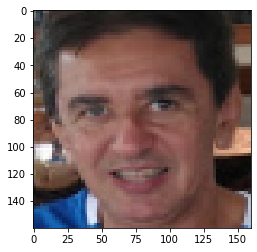

In [45]:
# plot face 
plt.imshow(img)
plt.show()

In [46]:
# convert to pixels
img_pixels = np.asarray(img)/255.
# use the pretrained model to generate the embeddings 
img_pixels = np.expand_dims(img_pixels, axis=0)
img_embeddings = model.predict(img_pixels)
# normalize input vectors (L2 norm)
in_encoder = Normalizer(norm='l2')
img_embeddings = in_encoder.transform(img_embeddings)

In [47]:
# predict image
pred = svc_model.predict(img_embeddings)
pred_prob = svc_model.predict_proba(img_embeddings)
class_probability = pred_prob[0,pred[0]] * 100
print('Predicted: %s (%.2f)' % (pred[0], class_probability))

Predicted: 11 (8.46)


In [48]:
# using a threshold
if class_probability >= 30:
    print('Predicted: %s (%.2f)' % (pred[0], class_probability))
else:
    print('Unknown person')

Unknown person


In [49]:
# shows instance probabilities for each class
pred_prob[0] * 100

array([3.90029696, 4.20072847, 4.98236979, 2.78248245, 3.10120246,
       3.8025954 , 5.50504839, 3.68491955, 8.24266263, 7.65478904,
       5.94897539, 8.45543667, 2.90241785, 2.577428  , 9.14018572,
       6.37931151, 2.29533142, 2.74116865, 3.03032282, 8.67232683])

# Fim

Esses foram os passos para criação de aplicações envolvendo reconhecimento facial.

--------------------------------